# Détection de fraude par carte bancaire : analyse exploratoire (EDA)

**Objectif.** Comprendre les données avant la modélisation : qualité des données, déséquilibre des classes, rôle de `Amount` et `Time`, pouvoir discriminant des variables `V1` à `V28`.

**Plan du notebook**
1. Chargement et aperçu des données
2. Valeurs manquantes et doublons
3. Variable cible `Class`
4. Variable `Amount`
5. Variable `Time`
6. Variables `V1` à `V28`
7. Synthèse, limites et suite du projet
8. Sauvegarde de la base enrichie

## 1. Chargement et aperçu des données

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score


df = pd.read_csv("../data/raw/creditcard.csv")

In [2]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

La base contient **284 807 transactions** et **31 variables**, toutes numériques :

- `Time` : nombre de secondes écoulées depuis la première transaction du jeu de données ;
- `Amount` : montant de la transaction ;
- `V1` à `V28` : variables **anonymisées**, issues d'une analyse en composantes principales (ACP) réalisée par le fournisseur du jeu de données (confidentialité) ;
- `Class` : variable cible (0 = transaction normale, 1 = fraude).

`Time` et `Amount` sont donc les deux seules variables « brutes » : ce sont aussi les seules dont le sens est lisible.

## 2. Valeurs manquantes et doublons

### 2.1 Valeurs manquantes

In [4]:
df.isna().sum().sort_values(ascending=False).head(10)

Time    0
V1      0
V2      0
V3      0
V4      0
V5      0
V6      0
V7      0
V8      0
V9      0
dtype: int64

In [5]:
print("Nombre total de valeurs manquantes :", df.isna().sum().sum())

Nombre total de valeurs manquantes : 0


La base ne contient **aucune valeur manquante**.

### 2.2 Doublons

In [6]:
duplicates = df.duplicated().sum()
print("Nombre de doublons :", duplicates)
print("Pourcentage :", round(duplicates / len(df) * 100, 2), "%")

Nombre de doublons : 1081
Pourcentage : 0.38 %


In [11]:
dup = df[df.duplicated()]

print("Répartition des classes parmi les doublons :")
print(dup["Class"].value_counts())
print()
print("En pourcentage :")
print((dup["Class"].value_counts(normalize=True) * 100).round(2))

Répartition des classes parmi les doublons :
Class
0    1062
1      19
Name: count, dtype: int64

En pourcentage :
Class
0    98.24
1     1.76
Name: proportion, dtype: float64


In [12]:
fraud_duplicates = dup["Class"].eq(1).sum()
total_fraud = df["Class"].eq(1).sum()

print("Fraudes parmi les doublons :", fraud_duplicates)
print("Fraudes totales            :", total_fraud)
print("Part des fraudes concernées :", round(fraud_duplicates / total_fraud * 100, 2), "%")

global_rate = df["Class"].mean() * 100
dup_rate = dup["Class"].mean() * 100
print()
print(f"Taux de fraude global     : {global_rate:.3f} %")
print(f"Taux de fraude (doublons) : {dup_rate:.3f} %")
print(f"Rapport                   : {dup_rate / global_rate:.1f}")

Fraudes parmi les doublons : 19
Fraudes totales            : 492
Part des fraudes concernées : 3.86 %

Taux de fraude global     : 0.173 %
Taux de fraude (doublons) : 1.758 %
Rapport                   : 10.2


**Bilan de l'analyse des doublons**

- 284 807 transactions, dont **1 081 doublons exacts** (environ 0,38 %) ;
- 492 fraudes au total, dont **19 dans les doublons** ;
- les doublons sont composés à environ 98 % de transactions normales et à environ **1,8 %** de fraudes ;
- **3,86 %** de toutes les fraudes se trouvent donc dans des observations identifiées comme doublons ;
- le taux de fraude parmi les doublons est environ **10,2 fois** supérieur à celui de l'ensemble du jeu de données.

**Décision.** Le jeu de données original est conservé pour l'instant : les doublons sont documentés, mais pas supprimés automatiquement, car ils contiennent une part non négligeable de fraudes.

**Suite prévue : analyse de sensibilité** lors de la modélisation.

| Modèle | Données | Objectif |
|---|---|---|
| A | doublons conservés | référence |
| B | doublons supprimés | mesurer l'effet des doublons sur les performances |

Une éventuelle fuite entre jeu d'entraînement et jeu de test (même ligne dans les deux) sera également vérifiée.

## 3. Variable cible `Class`

In [13]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [14]:
fraud_ratio = df["Class"].value_counts(normalize=True)
print(fraud_ratio.round(5))

Class
0    0.99827
1    0.00173
Name: proportion, dtype: float64


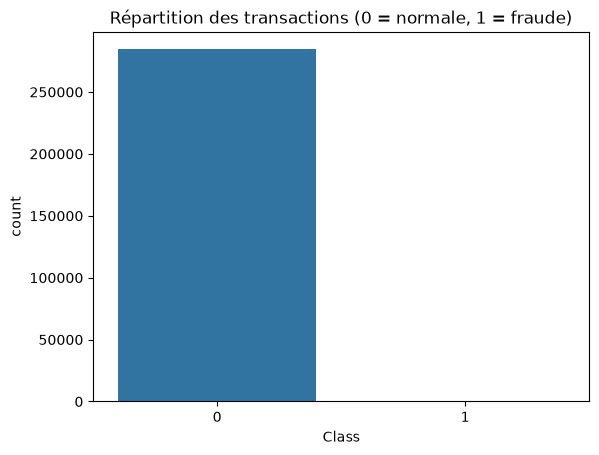

In [15]:
sns.countplot(x="Class", data=df)
plt.title("Répartition des transactions (0 = normale, 1 = fraude)")
plt.show()

Le déséquilibre est très marqué : **284 315 transactions normales (99,83 %)** contre **492 fraudes (0,17 %)**.

**Conséquence.** Un modèle qui prédirait toujours « normale » aurait une accuracy d'environ 99,8 % tout en étant totalement inutile pour détecter les fraudes. L'**accuracy ne sera donc pas utilisée comme métrique principale** : on s'appuiera sur le rappel (recall), la précision et la courbe précision-rappel (PR-AUC).

In [17]:
df_normal = df[df["Class"] == 0]
df_fraud = df[df["Class"] == 1]

## 4. Variable `Amount`

Nous étudions la distribution des montants et cherchons dans quelle mesure `Amount` peut aider à distinguer les transactions normales des fraudes.

### 4.1 Distribution globale

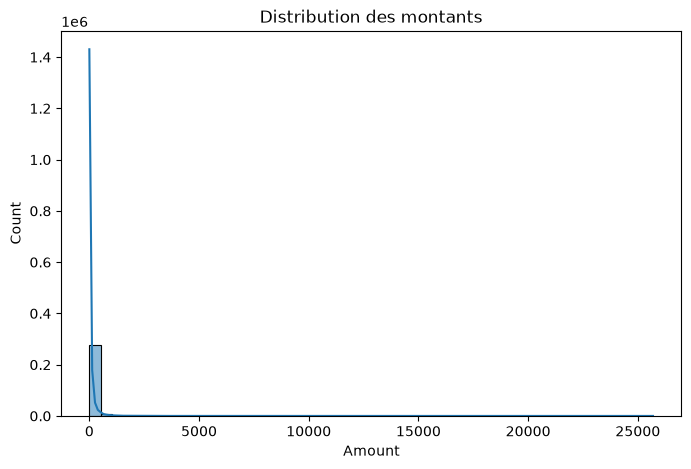

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Amount"], bins=50, kde=True)
plt.title("Distribution des montants")
plt.show()

In [19]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [20]:
print("Skewness de Amount :", round(df["Amount"].skew(), 2))

Skewness de Amount : 16.98


La moyenne est nettement supérieure à la médiane : la distribution est **fortement asymétrique à droite**, ce que confirme le coefficient d'asymétrie (skewness), très élevé.

- la moitié des transactions ont un montant inférieur à **22** ;
- 75 % des transactions ont un montant inférieur à **77** ;
- le montant maximal atteint **25 691**.

La plupart des transactions sont donc de faible montant, et quelques valeurs très élevées tirent la moyenne vers le haut.

### 4.2 Montants selon la classe

In [22]:
df.groupby("Class")["Amount"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.29,22.00,250.11,0.0,25691.16
1,492,122.21,9.25,256.68,0.0,2125.87


- Le montant **moyen** des fraudes est supérieur à celui des transactions normales (**122,21** contre **88,29**).
- Mais la **médiane** montre l'inverse : 50 % des transactions normales ont un montant inférieur ou égal à **22**, contre **9,25** pour les fraudes.

Dans les deux classes, la moyenne est nettement supérieure à la médiane : les distributions sont asymétriques à droite et quelques valeurs élevées tirent la moyenne vers le haut, en particulier chez les fraudes. La moyenne seule ne suffit donc pas pour comparer les classes : la médiane et les quartiles sont plus robustes.

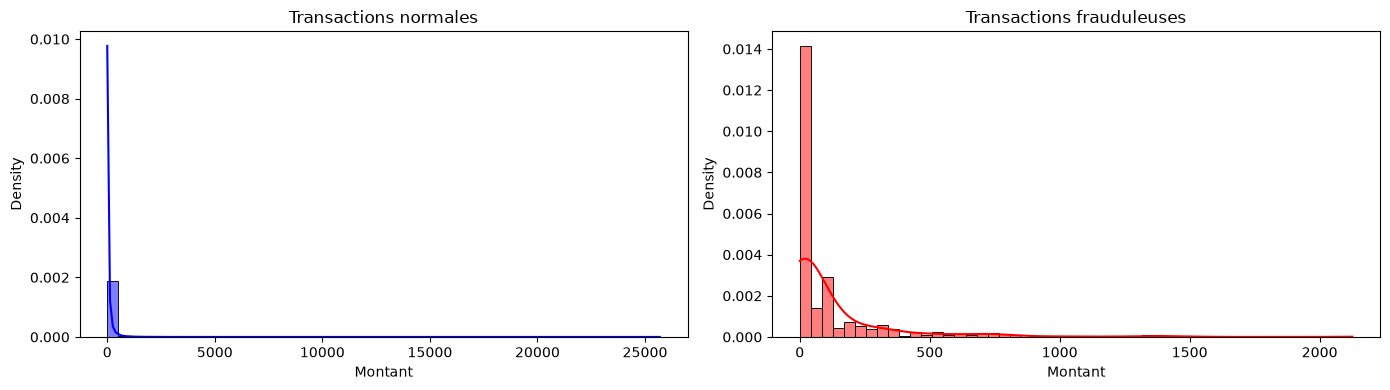

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=df_normal, x="Amount", bins=50, kde=True, stat="density", color="blue", ax=ax[0])
ax[0].set_title("Transactions normales")
ax[0].set_xlabel("Montant")

sns.histplot(data=df_fraud, x="Amount", bins=50, kde=True, stat="density", color="red", ax=ax[1])
ax[1].set_title("Transactions frauduleuses")
ax[1].set_xlabel("Montant")

plt.tight_layout()
plt.show()

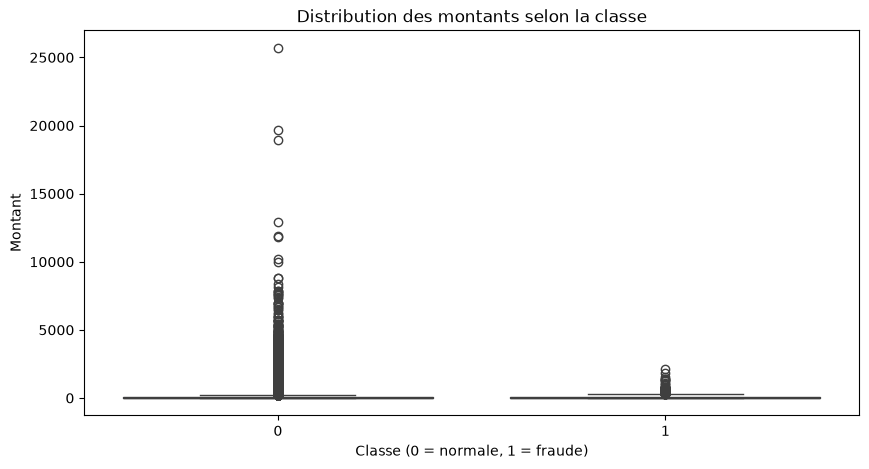

In [22]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Class", y="Amount")
plt.title("Distribution des montants selon la classe")
plt.xlabel("Classe (0 = normale, 1 = fraude)")
plt.ylabel("Montant")
plt.show()

Dans les deux classes, les montants sont majoritairement faibles (zone 0 à 500 pour les transactions normales, 0 à 250 pour les fraudes), avec une asymétrie à droite et de nombreuses valeurs extrêmes. Les transactions normales ont davantage de valeurs extrêmes, ce qui s'explique en partie par leur bien plus grand nombre. La présence de valeurs extrêmes chez les fraudes reste notable compte tenu de leur faible effectif. Ces valeurs ne seront pas supprimées automatiquement : elles peuvent être informatives.

### 4.3 Montants élevés (supérieurs à 500)

In [25]:
gros = df[df["Amount"] > 500]
print("Transactions > 500          :", len(gros))
print("dont frauduleuses           :", int(gros["Class"].sum()))
print("Taux de fraude (> 500)      :", round(gros["Class"].mean() * 100, 3), "%")
print("Montant moyen (> 500)       :", round(gros["Amount"].mean(), 2))

Transactions > 500          : 9142
dont frauduleuses           : 35
Taux de fraude (> 500)      : 0.383 %
Montant moyen (> 500)       : 1051.81


**Conclusion.** Un montant élevé ne signifie pas qu'une transaction est frauduleuse : parmi les 9 142 transactions supérieures à 500, 35 sont des fraudes, soit un taux de 0,383 %. C'est environ 2,2 fois le taux global (0,173 %), donc un montant élevé augmente un peu le risque, mais les fraudes restent très minoritaires. Le montant doit être analysé avec les autres variables.

### 4.4 Fraudes de faible montant (inférieur à 50)

In [26]:
fraudes_petites = df[(df["Class"] == 1) & (df["Amount"] < 50)]
petites = df[df["Amount"] < 50]

print("Fraudes avec Amount < 50 :", len(fraudes_petites))
print("Part des fraudes ayant Amount < 50 :", round(len(fraudes_petites) / len(df_fraud) * 100, 2), "%")
print("Taux de fraude parmi les transactions Amount < 50 :", round(len(fraudes_petites) / len(petites) * 100, 3), "%")

Fraudes avec Amount < 50 : 305
Part des fraudes ayant Amount < 50 : 61.99 %
Taux de fraude parmi les transactions Amount < 50 : 0.161 %


Environ **62 % des fraudes** ont un montant inférieur à 50 : la majorité des fraudes concernent de petits montants. Pourtant, seulement **0,16 %** des transactions de moins de 50 sont frauduleuses.

Ces deux résultats ne se contredisent pas : le premier est calculé **parmi les fraudes**, le second **parmi toutes les petites transactions**. Comme les transactions normales sont aussi majoritairement de faible montant, un petit montant ne suffit pas à signaler une fraude.

### 4.5 Catégorisation des montants (`Small` / `Large`)

`Small` : montant inférieur à 50 ; `Large` : autres montants.

In [29]:
df["Amount_category"] = np.where(df["Amount"] < 50, "Small", "Large")

print(df.groupby(["Class", "Amount_category"]).size().unstack())
print()
print("Taux de fraude par catégorie (%) :")
print((df.groupby("Amount_category")["Class"].mean() * 100).round(4))

Amount_category  Large   Small
Class                         
0                94916  189399
1                  187     305

Taux de fraude par catégorie (%) :
Amount_category
Large    0.1966
Small    0.1608
Name: Class, dtype: float64


Le taux de fraude est légèrement plus élevé pour les transactions `Large` (**0,1966 %**) que pour les `Small` (**0,1608 %**), mais la différence reste faible. `Amount` semble potentiellement informative, mais insuffisante à elle seule.

### 4.6 Comparaison des distributions (échelle brute)

On utilise `stat="density"` pour comparer les formes malgré le très fort déséquilibre entre classes.

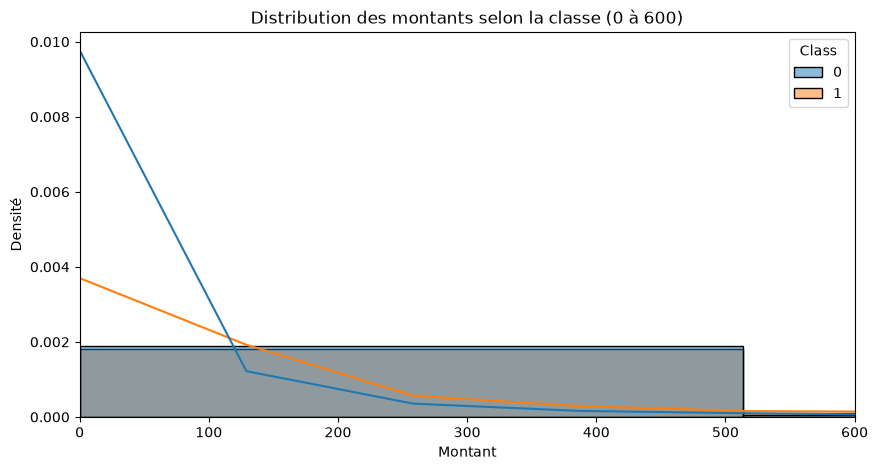

In [31]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df, x="Amount", hue="Class",
    bins=50, kde=True, stat="density", common_norm=False
)
plt.xlim(0, 600)
plt.xlabel("Montant")
plt.ylabel("Densité")
plt.title("Distribution des montants selon la classe (0 à 600)")
plt.show()

Les distributions diffèrent entre les deux classes, donc `Amount` contient une information utile. Leur chevauchement important montre toutefois que `Amount` seule ne permet pas de séparer efficacement les fraudes. Sur cette échelle brute, la forme reste toutefois difficile à lire : c'est l'objet de la section suivante.

### 4.7 Transformation logarithmique : `log1p(Amount)`

**Le problème.** Quelques très gros montants « écrasent » le graphique : presque toutes les barres sont collées à gauche et la forme de la distribution n'est plus visible.

**La solution.** Le logarithme rapproche les grandes valeurs des petites : les écarts sont mesurés en proportion (passer de 10 à 100 compte autant que passer de 100 à 1 000). On utilise `log1p(x) = log(1 + x)` plutôt que `log(x)` car certaines transactions ont un montant de **0**, dont le logarithme n'existe pas.

**Intérêt**
- *Graphiques* : la distribution devient lisible.
- *Régression logistique* : ce modèle suppose un effet régulier de chaque variable ; avec quelques montants énormes, ce n'est pas le cas. Le `StandardScaler` seul ne corrige pas l'asymétrie (il change l'échelle mais pas la forme).
- *Arbres de décision* (Random Forest, XGBoost) : sans effet, car ils ne regardent que l'ordre des valeurs. `Amount` brut pourra être conservé pour ces modèles.

**Pas de fuite de données.** La transformation est une formule fixe qui n'apprend rien sur les données : elle peut être calculée avant la séparation entre jeu d'entraînement et jeu de test.

Skewness Amount     : 16.98
Skewness Amount_log : 0.16


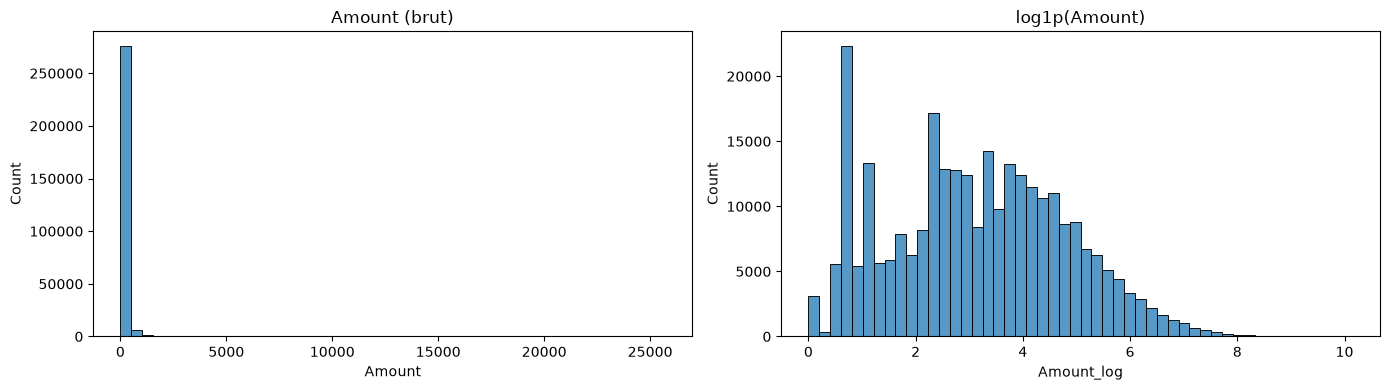

In [32]:
# Transformation logarithmique : log(1 + Amount), valable aussi pour Amount = 0
df["Amount_log"] = np.log1p(df["Amount"])

print("Skewness Amount     :", round(df["Amount"].skew(), 2))
print("Skewness Amount_log :", round(df["Amount_log"].skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Amount"], bins=50, ax=ax[0])
ax[0].set_title("Amount (brut)")
sns.histplot(df["Amount_log"], bins=50, ax=ax[1])
ax[1].set_title("log1p(Amount)")
plt.tight_layout()
plt.show()

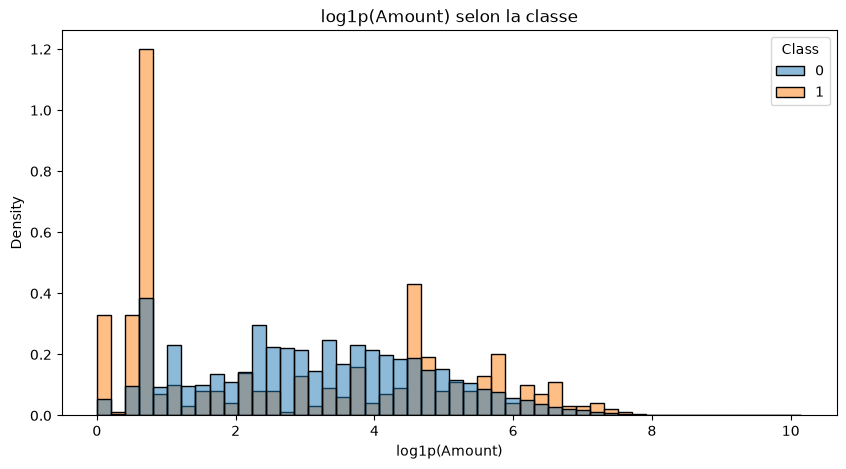

In [33]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df, x="Amount_log", hue="Class",
    bins=50, stat="density", common_norm=False
)
plt.title("log1p(Amount) selon la classe")
plt.xlabel("log1p(Amount)")
plt.show()

In [35]:
df.groupby("Class")["Amount_log"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,3.15,1.66,0.0,1.89,3.14,4.36,10.15
1,492.0,2.82,2.21,0.0,0.69,2.33,4.67,7.66


**Lecture des graphiques**

- La transformation fait apparaître la vraie forme de la distribution : étalée, avec plusieurs pics, jusqu'à environ 10 (le plus gros montant).
- Les pics à 0,7 et 1,1 correspondent à des montants « ronds » très fréquents : `log1p(1)` (environ 1 €) et `log1p(2)` (environ 2 €). Le pic à 2,3 correspond à environ 9 à 10 €.
- Les fraudes ne suivent pas la même forme que les transactions normales : **un très gros pic vers 0,7** (montant d'environ 1), qui contient grossièrement **un quart des fraudes** contre moins de 8 % des transactions normales ; d'autres petits pics près de 0 et 0,5 ; un pic vers 4,5 et quelques pics entre 6 et 7.

| | Normales | Fraudes | Lecture |
|---|---|---|---|
| Médiane | 3,14 | 2,33 | `expm1(2,33)` ≈ **9,3** contre `expm1(3,14)` ≈ **22** |
| 25 % | 1,89 | **0,69** | un quart des fraudes ont un montant d'environ **1** ou moins |
| 75 % | 4,36 | 4,67 | côté gros montants, les fraudes dépassent légèrement |
| Écart-type | 1,66 | **2,21** | les fraudes sont plus dispersées |

`expm1(2,3) = exp(2,3)-1`

Les fraudes sont donc à la fois **plus souvent de très faible montant** et **plus dispersées**.

**Points de prudence**
- Il n'y a que 492 fraudes : chaque barre est bruitée. Le pic à 0,7 est assez important pour être crédible ; les petites bosses vers 6 et 7 beaucoup moins.
- L'hypothèse d'un « test de carte à 1 € » est plausible (comportement connu en fraude), mais rien dans ces données ne la prouve.
- Les pics au-delà de 4,5 sont à vérifier avant toute interprétation (valeurs exactes de `Amount`).

**Vérifications chiffrées**

In [32]:
# Taux de fraude pour les montants <= 1
petits = df["Amount"] <= 1
resume = df.groupby(petits)["Class"].agg(transactions="count", fraudes="sum", taux="mean")
resume["taux_fraude_%"] = (resume["taux"] * 100).round(3)
resume.index = resume.index.map({True: "Amount <= 1", False: "Amount > 1"})
print(resume[["transactions", "fraudes", "taux_fraude_%"]])
print()
print("Taux de fraude global (%) :", round(df["Class"].mean() * 100, 3))
print("Part des fraudes avec Amount <= 1 (%)             :", round((df_fraud["Amount"] <= 1).mean() * 100, 1))
print("Part des transactions normales avec Amount <= 1 (%) :", round((df_normal["Amount"] <= 1).mean() * 100, 1))

             transactions  fraudes  taux_fraude_%
Amount                                           
Amount > 1         254315      311          0.122
Amount <= 1         30492      181          0.594

Taux de fraude global (%) : 0.173
Part des fraudes avec Amount <= 1 (%)             : 36.8
Part des transactions normales avec Amount <= 1 (%) : 10.7


In [36]:
# Montants les plus fréquents dans chaque classe
print("Fraudes : montants les plus fréquents")
print(df_fraud["Amount"].value_counts().head(10).rename_axis("Amount").reset_index(name="effectif").to_string(index=False))
print()
print("Normales : montants les plus fréquents")
print(df_normal["Amount"].value_counts().head(10).rename_axis("Amount").reset_index(name="effectif").to_string(index=False))

Fraudes : montants les plus fréquents
 Amount  effectif
   1.00       113
   0.00        27
  99.99        27
   0.76        17
   0.77        10
   0.01         5
   3.79         4
   2.00         4
   1.10         3
   0.68         3

Normales : montants les plus fréquents
 Amount  effectif
   1.00     13575
   1.98      6044
   0.89      4872
   9.99      4746
  15.00      3280
   0.76      2981
  10.00      2950
   1.29      2892
   1.79      2622
   0.99      2304


**Résultats des vérifications**

- **Taux de fraude pour `Amount <= 1`** : **0,594 %** (181 fraudes sur 30 492 transactions), soit environ **3,4 fois** le taux global (0,173 %). Au-dessus de 1, le taux n'est que de 0,122 %.
- **36,8 %** des fraudes ont un montant inférieur ou égal à 1, contre **10,7 %** des transactions normales.
- **Montants les plus fréquents dans les fraudes** : **1,00** (113 fraudes), **0,00** (27), **99,99** (27), **0,76** (17), **0,77** (10).
- **Montants les plus fréquents dans les transactions normales** : **1,00** (13 575), **1,98** (6 044), **0,89** (4 872), **9,99** (4 746), **15,00** (3 280).

**Lecture.** Le montant exact de 1,00 concerne 113 fraudes pour 13 575 transactions normales, soit un taux d'environ 0,83 %, presque **5 fois** le taux global. Les montants 0,00 et 99,99 apparaissent chacun 27 fois chez les fraudes mais ne figurent pas parmi les 10 montants les plus fréquents des transactions normales (moins de 2 304 occurrences) : leur taux de fraude dépasse donc 1 %. Certains montants précis sont ainsi sur-représentés parmi les fraudes. L'hypothèse d'un « test de carte » à très petit montant est plausible mais ne peut pas être démontrée avec ces données.

**Conclusion sur `Amount`.** La transformation `log1p` réduit fortement l'asymétrie de `Amount` (skewness de 16,98 à 0,16) et rend la distribution lisible. Sur l'échelle logarithmique, les fraudes diffèrent des transactions normales : leur médiane est plus basse (≈ 9,3 contre ≈ 22), environ 37 % d'entre elles ont un montant inférieur ou égal à 1 (contre 11 % des transactions normales), et leur dispersion est plus grande. Les deux distributions se chevauchent toutefois largement entre ces extrêmes : `Amount` reste informative mais insuffisante à elle seule.

**Conséquence pour la modélisation.** L'effet de `Amount` n'est pas monotone (le risque est plus élevé pour de très petits montants, puis redescend, puis remonte légèrement). Les modèles à base d'arbres le captent directement ; pour la régression logistique, `Amount_log` pourra être complétée par un indicateur « petit montant ».

## 5. Variable `Time`

`Time` est le nombre de secondes écoulées depuis la première transaction du jeu de données.

### 5.1 Distribution générale

In [37]:
df["Time"].describe()

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64

In [38]:
print("Skewness de Time :", round(df["Time"].skew(), 4))

Skewness de Time : -0.0356


`Time` varie de 0 à environ **172 792 secondes** (soit un peu moins de 48 heures). La moyenne (94 813,86) est supérieure à la médiane (84 692), ce qui pourrait suggérer une asymétrie à droite ; mais le coefficient d'asymétrie est très proche de zéro (**-0,0356**). La distribution est donc **approximativement symétrique**, sans asymétrie importante.

In [36]:
df.groupby("Class")["Time"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,94838.2,47484.0,0.0,54230.0,84711.0,139333.0,172792.0
1,492.0,80746.8,47835.4,406.0,41241.5,75568.5,128483.0,170348.0


La distribution de `Time` semble décalée vers des valeurs plus faibles pour les fraudes, ce qui suggère une information discriminante. Cependant, le chevauchement important des distributions montre que `Time` ne permet pas, seule, de séparer les deux classes.

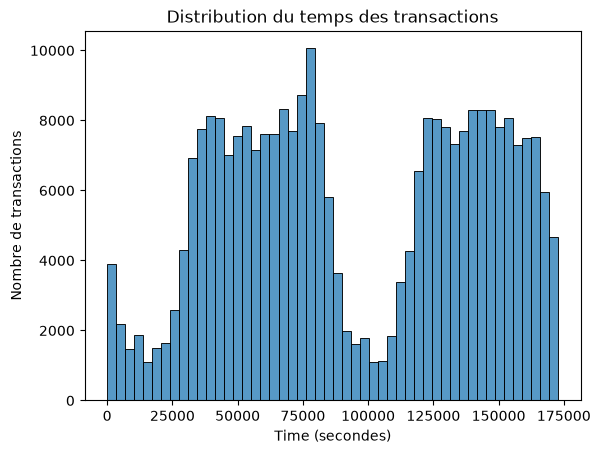

In [37]:
sns.histplot(data=df, x="Time", bins=50)
plt.title("Distribution du temps des transactions")
plt.xlabel("Time (secondes)")
plt.ylabel("Nombre de transactions")
plt.show()

Les transactions ne sont pas réparties uniformément. On distingue **deux grandes zones de concentration** (environ 30 000 à 85 000 secondes, puis 120 000 à 170 000 secondes) séparées par une forte baisse d'activité autour de 90 000 à 110 000 secondes. La distribution est donc **bimodale**, ce qui est cohérent avec une alternance jour / nuit sur deux jours (sous réserve de l'hypothèse faite plus bas sur l'origine de `Time`).

### 5.2 Taux de fraude par tranche de temps

Les tranches sont définies par `pd.cut` sur l'ensemble du jeu de données : il s'agit d'une exploration, pas d'une variable destinée au modèle.

In [38]:
df["Time_bin"] = pd.cut(df["Time"], bins=10)

time_analysis = df.groupby("Time_bin", observed=True)["Class"].agg(
    total_transactions="count",
    nombre_fraudes="sum",
    taux_fraude="mean",
)
time_analysis["taux_fraude"] = time_analysis["taux_fraude"] * 100
time_analysis.round(3)

,total_transactions,nombre_fraudes,taux_fraude
Time_bin,,,
"(-172.792, 17279.2]",10510,42,0.400
"(17279.2, 34558.4]",16955,48,0.283
"(34558.4, 51837.6]",38526,79,0.205
"(51837.6, 69116.8]",38550,63,0.163
"(69116.8, 86396.0]",40243,49,0.122
"(86396.0, 103675.2]",10145,68,0.670
"(103675.2, 120954.4]",17161,11,0.064
"(120954.4, 138233.6]",38951,34,0.087
"(138233.6, 155512.8]",40779,66,0.162


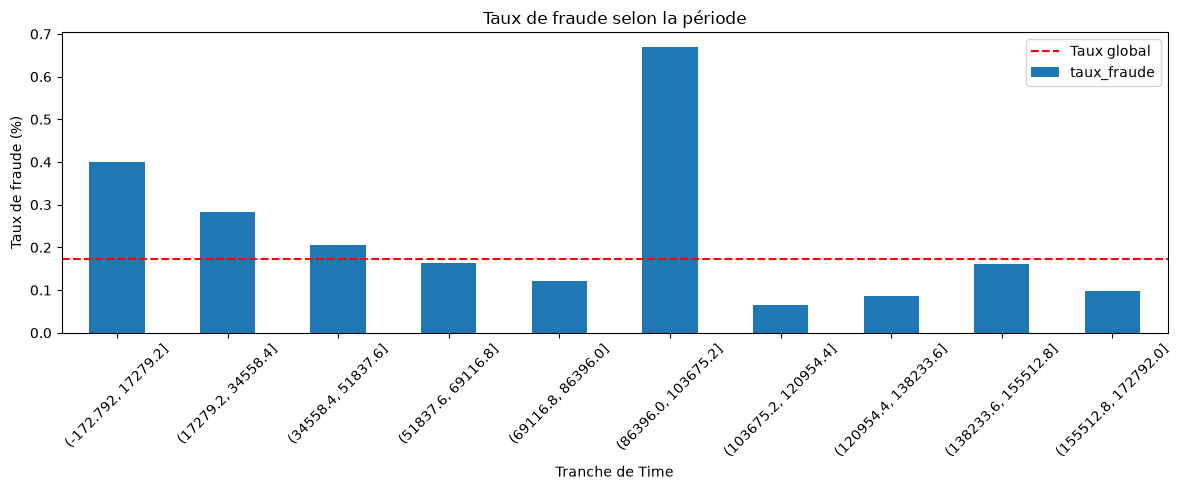

In [39]:
plt.figure(figsize=(12, 5))
time_analysis["taux_fraude"].plot(kind="bar")
plt.axhline(df["Class"].mean() * 100, color="red", linestyle="--", label="Taux global")
plt.title("Taux de fraude selon la période")
plt.xlabel("Tranche de Time")
plt.ylabel("Taux de fraude (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

*Note : la moyenne de `Class` (0 ou 1) correspond directement à la proportion de fraudes.*

Le taux de fraude varie selon les tranches. Il est maximal dans l'intervalle **[86 396 ; 103 675]** (**0,67 %**) et minimal dans l'intervalle **[103 675 ; 120 954]** (**0,064 %**), pour un taux global de **0,173 %**. La tranche 3 concentre le plus grand nombre de fraudes en valeur absolue (**79**), mais la tranche 6 a le taux le plus élevé malgré un nombre de transactions plus faible.

Ces tranches sont larges (près de 5 heures) : l'analyse par heure du cycle, plus fine, est présentée ci-dessous.

### 5.3 Heure du cycle de 24 heures

Question : **existe-t-il des moments du cycle de 24 heures où la fraude est davantage représentée ?**

- `Time_hours` : position sur la période globale de 48 heures ;
- `Hour_cycle` : position dans un cycle de 24 heures (`Time % 86400`, converti en heures) ;
- `Hour` : partie entière de `Hour_cycle` (0 à 23).

**Hypothèse importante.** Le jeu de données ne précise pas l'origine de `Time`. Calculer l'heure par `Time % 86400` suppose que `Time = 0` correspond à minuit. Le creux de volume observé entre les heures 1 et 6 suggère que c'est approximativement le cas, mais cela reste une **hypothèse** (un décalage d'une à deux heures est possible). On parle donc d'« heure du cycle ».

In [39]:
df["Time_hours"] = df["Time"] / 3600
df["Hour_cycle"] = (df["Time"] % 86400) / 3600
df["Hour"] = df["Hour_cycle"].astype(int)

df[["Time_hours", "Hour_cycle", "Hour"]].describe().round(2)

,Time_hours,Hour_cycle,Hour
count,284807.00,284807.00,284807.00
mean,26.34,14.54,14.05
std,13.19,5.85,5.84
min,0.00,0.00,0.00
25%,15.06,10.60,10.00
50%,23.53,15.01,15.00
75%,38.70,19.33,19.00
max,48.00,24.00,23.00


In [40]:
hour_analysis = df.groupby("Hour")["Class"].agg(
    total_transactions="count",
    nombre_fraudes="sum",
    taux_fraude="mean",
)
hour_analysis["taux_fraude"] = hour_analysis["taux_fraude"] * 100


def wilson_ci(k, n, z=1.96):
    """Intervalle de confiance de Wilson (en %) pour une proportion k/n."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    marge = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centre - marge) * 100, (centre + marge) * 100


low, high = wilson_ci(hour_analysis["nombre_fraudes"], hour_analysis["total_transactions"])
hour_analysis["ic_bas"] = low
hour_analysis["ic_haut"] = high

hour_analysis.round(3)

,total_transactions,nombre_fraudes,taux_fraude,ic_bas,ic_haut
Hour,,,,,
0,7695,6,0.078,0.036,0.170
1,4220,10,0.237,0.129,0.436
2,3328,57,1.713,1.324,2.212
3,3492,17,0.487,0.304,0.778
4,2209,23,1.041,0.695,1.558
5,2990,11,0.368,0.206,0.658
6,4101,9,0.219,0.116,0.417
7,7243,23,0.318,0.212,0.476
8,10276,9,0.088,0.046,0.166


**Pourquoi un intervalle de confiance ?** Un taux calculé sur peu de transactions est instable : quelques fraudes de plus ou de moins le font beaucoup varier, alors qu'un taux calculé sur des milliers de transactions est fiable. L'intervalle de confiance à 95 % (méthode de Wilson, adaptée aux petits effectifs) donne la fourchette dans laquelle se situe probablement le vrai taux : **étroite** quand les données sont nombreuses, **large** quand elles sont rares. Si l'intervalle d'une heure ne contient pas le taux global (ligne rouge), cette heure s'en distingue de façon fiable.

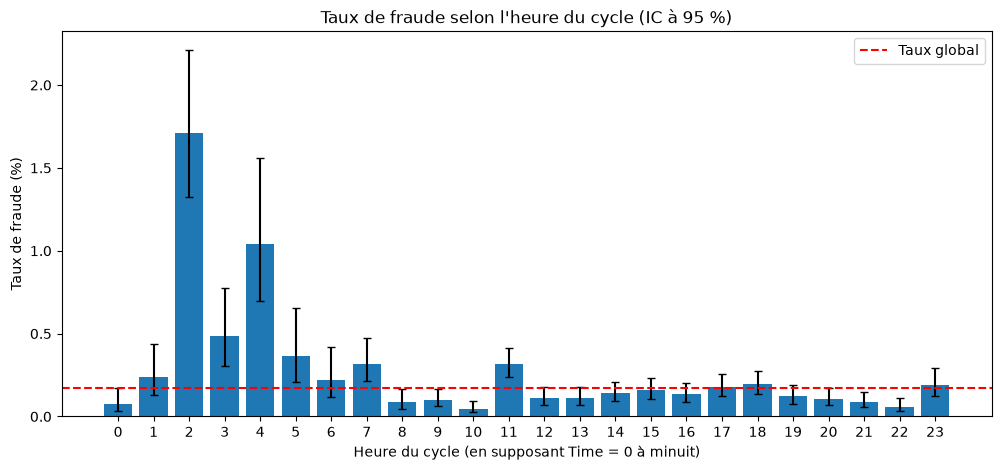

In [41]:
taux_global = df["Class"].mean() * 100

plt.figure(figsize=(12, 5))
erreurs = [
    hour_analysis["taux_fraude"] - hour_analysis["ic_bas"],
    hour_analysis["ic_haut"] - hour_analysis["taux_fraude"],
]
plt.bar(hour_analysis.index, hour_analysis["taux_fraude"], yerr=erreurs, capsize=3)
plt.axhline(taux_global, color="red", linestyle="--", label="Taux global")
plt.title("Taux de fraude selon l'heure du cycle (IC à 95 %)")
plt.xlabel("Heure du cycle (en supposant Time = 0 à minuit)")
plt.ylabel("Taux de fraude (%)")
plt.xticks(range(24))
plt.legend()
plt.show()

In [42]:
# Classement automatique des heures par rapport au taux global
au_dessus = hour_analysis.index[hour_analysis["ic_bas"] > taux_global].tolist()
en_dessous = hour_analysis.index[hour_analysis["ic_haut"] < taux_global].tolist()
neutres = [h for h in hour_analysis.index if h not in au_dessus + en_dessous]

print("Nettement au-dessus du taux global :", au_dessus)
print("Nettement en dessous               :", en_dessous)
print("Non distinguables de la moyenne    :", neutres)

# Heures 1 à 7 regroupées
nuit = df["Hour"].between(1, 7)
print()
print("Heures 1 à 7 : part des fraudes        :", round(df.loc[nuit, "Class"].sum() / df["Class"].sum() * 100, 1), "%")
print("Heures 1 à 7 : part des transactions   :", round(nuit.mean() * 100, 1), "%")
print("Heures 1 à 7 : taux de fraude          :", round(df.loc[nuit, "Class"].mean() * 100, 3), "%")

Nettement au-dessus du taux global : [2, 3, 4, 5, 7, 11]
Nettement en dessous               : [0, 8, 9, 10, 20, 21, 22]
Non distinguables de la moyenne    : [1, 6, 12, 13, 14, 15, 16, 17, 18, 19, 23]

Heures 1 à 7 : part des fraudes        : 30.5 %
Heures 1 à 7 : part des transactions   : 9.7 %
Heures 1 à 7 : taux de fraude          : 0.544 %


**Lecture du graphique** (taux global : **0,173 %**)

*Heures nettement au-dessus du taux global* (intervalle entièrement au-dessus de la ligne rouge) :

| Heure | Taux | IC 95 % | Lecture |
|---|---|---|---|
| **2** | 1,71 % | 1,32 – 2,21 | très net, environ 10 fois le taux global |
| **4** | 1,04 % | 0,70 – 1,56 | très net, malgré seulement 2 209 transactions |
| **3** | 0,49 % | 0,30 – 0,78 | net |
| **11** | 0,31 % | 0,24 – 0,41 | net, intervalle étroit (16 856 transactions) |
| **5** et **7** | 0,37 % et 0,32 % | 0,21 – 0,66 et 0,21 – 0,48 | au-dessus, mais borne basse proche du taux global |

- L'heure 11 est une heure de journée à fort volume : la fraude ne se limite pas à la nuit.
- **Heures 1 à 7 regroupées** : 150 fraudes sur 492 (**30,5 %**) pour seulement **9,7 %** des transactions, soit un taux d'environ **0,54 %**, trois fois le taux global.

*Heures nettement en dessous du taux global* : 0, 8, 9, 10, 20, 21 et 22.

*Heures non distinguables de la moyenne* (l'intervalle touche la ligne rouge) : 1, 6, 12 à 19 et 23.

**Points de prudence**
- **Comparaisons multiples** : 24 heures sont testées à 95 %, donc environ une heure sera « significative » par hasard. Les résultats marginaux (heures 5 et 7) valent peu ; les intervalles très éloignés de la ligne (heures 2 et 4) sont robustes.
- **Intervalles probablement optimistes** : la formule suppose des transactions indépendantes, alors que les fraudes arrivent souvent en rafales (une même carte utilisée plusieurs fois).
- **Faible volume** : les heures peu fournies ont des intervalles larges, à ne pas sur-interpréter.
- **Deux jours mélangés** : vérifié ci-dessous.

### 5.4 Vérification : les deux jours séparément

Chaque heure regroupe les deux jours du jeu de données. Un pic pourrait provenir d'une seule attaque survenue un jour donné.

In [43]:
df["Day"] = (df["Time"] // 86400).astype(int)  # 0 = premier jour, 1 = second jour

by_day = df.groupby(["Day", "Hour"])["Class"].agg(transactions="count", fraudes="sum")
by_day["taux_%"] = (by_day["fraudes"] / by_day["transactions"] * 100).round(3)

# Focus sur les heures d'intérêt
heures_focus = [2, 3, 4, 11]
focus = by_day.loc[(slice(None), heures_focus), :].unstack(level=0)
focus

transactions       fraudes     taux_%       
Day             0     1       0   1      0      1
Hour                                             
2            1576  1752      21  36  1.332  2.055
3            1821  1671      13   4  0.714  0.239
4            1082  1127       6  17  0.555  1.508
11           8517  8339      43  10  0.505  0.120

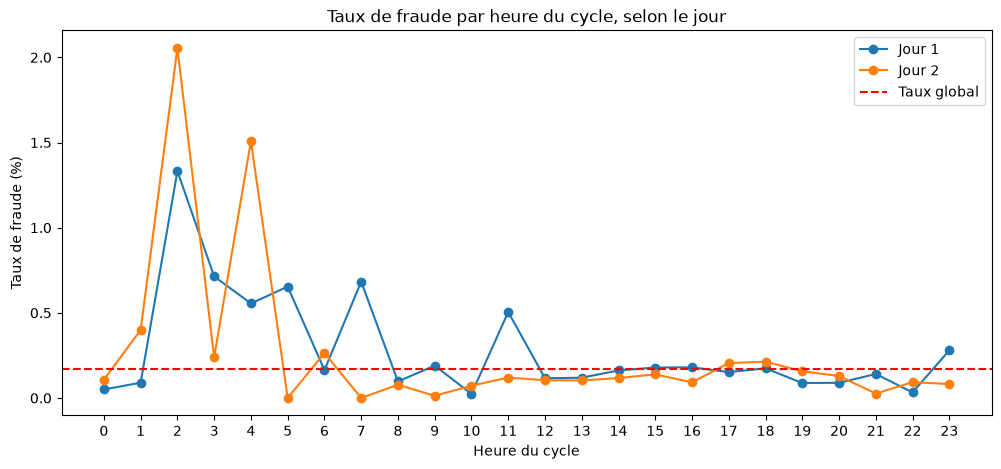

In [44]:
fig, ax = plt.subplots(figsize=(12, 5))
for day, label in [(0, "Jour 1"), (1, "Jour 2")]:
    s = by_day.loc[day]["taux_%"]
    ax.plot(s.index, s.values, marker="o", label=label)
ax.axhline(taux_global, color="red", linestyle="--", label="Taux global")
ax.set_title("Taux de fraude par heure du cycle, selon le jour")
ax.set_xlabel("Heure du cycle")
ax.set_ylabel("Taux de fraude (%)")
ax.set_xticks(range(24))
ax.legend()
plt.show()

**Résultat de la vérification.** Taux de fraude par heure du cycle et par jour (jour 1 = `Day` 0, jour 2 = `Day` 1 ; taux global : 0,173 %) :

| Heure | Jour 1 | Jour 2 | Lecture |
|---|---|---|---|
| **2** | 1,33 % (21 fraudes) | 2,05 % (36 fraudes) | très élevé les deux jours |
| **3** | 0,71 % (13) | 0,24 % (4) | surtout le jour 1 |
| **4** | 0,55 % (6) | 1,51 % (17) | au-dessus du taux global les deux jours, plus marqué le jour 2 |
| **11** | 0,50 % (43) | 0,12 % (10) | surtout le jour 1 ; le jour 2 est **sous** le taux global |

**Interprétation**
- **Heure 2** : le pic existe les **deux jours** (8 à 12 fois le taux global). C'est le signal le plus robuste, et il va dans le sens d'un véritable effet de l'heure.
- **Heure 4** : taux supérieur au taux global les deux jours, mais l'ampleur varie (3 fois le taux global le jour 1, près de 9 fois le jour 2). L'effet est probable, moins stable que celui de l'heure 2.
- **Heure 3** : le niveau est élevé surtout le jour 1 ; le jour 2, le taux est proche du taux global.
- **Heure 11** : 43 des 53 fraudes de cette heure surviennent le jour 1, et le jour 2 est sous le taux global. Ce pic est donc probablement un **événement ponctuel** (par exemple une attaque) et non un effet de l'heure.
- **Limite** : chaque case contient peu de fraudes (de 4 à 43), donc ces taux restent bruités.

**Lecture du graphique.** Les profils horaires des deux jours ne se superposent pas : seule l'heure 2 est fortement élevée les deux jours. Le jour 2 chute à l'heure 3 (0,24 %, sur 4 fraudes seulement) puis remonte à l'heure 4 (1,51 %), tandis que les heures 5 et 7 sont des pics du jour 1 uniquement (taux nul le jour 2). Les autres pics (heures 3, 4, 5, 7 et 11) sont irréguliers d'un jour à l'autre. Avec 4 à 43 fraudes par case, ces variations restent compatibles avec du bruit d'échantillonnage.

### 5.5 Conclusion sur `Time`

> En supposant que `Time = 0` correspond à minuit, le taux de fraude est nettement supérieur au taux global aux heures 2 à 4 (jusqu'à 1,71 % à l'heure 2, environ 10 fois le taux global). La vérification par jour confirme ce résultat pour l'heure 2 (élevée les deux jours) ; l'heure 4 reste au-dessus du taux global les deux jours mais de façon irrégulière, et le pic de l'heure 11 provient surtout du premier jour et semble ponctuel. Les heures 1 à 7 concentrent 30,5 % des fraudes pour 9,7 % des transactions. Pour les heures à faible volume, les intervalles de confiance sont larges et les différences marginales ne doivent pas être sur-interprétées. La contribution réelle de cette variable sera évaluée lors de la modélisation.

**Conséquence pour la modélisation.** L'effet de l'heure n'est ni linéaire ni monotone (plus élevé la nuit, bas en journée). Une régression logistique ne peut pas le capter si `Hour` est utilisée comme un entier, et elle ignore que 23h et 0h sont voisines :

- **Régression logistique** : encodage cyclique (`sin` et `cos` de l'heure) ou indicateur « nuit » (heures 1 à 7) ;
- **Arbres** (Random Forest, XGBoost) : `Hour` brute suffit.

## 6. Variables `V1` à `V28`

**Nature des variables.** `V1` à `V28` sont des **composantes d'une ACP** réalisées par le fournisseur du jeu de données : elles sont anonymisées et **non interprétables** (on ne sait pas à quelles variables d'origine elles correspondent). Par construction, des composantes principales sont **décorrélées entre elles**.

**Conséquences pour l'analyse**
- on ne cherche pas à donner un sens métier à une variable ;
- il n'y a pas de problème de multicolinéarité entre les `V` ;
- les valeurs extrêmes ne sont pas supprimées : en détection de fraude, elles sont souvent justement les fraudes ;
- toutes les `V` sont conservées pour la modélisation ; l'analyse ci-dessous sert à repérer celles qui portent le plus de signal.

In [46]:
v_cols = [f"V{i}" for i in range(1, 29)]

# Vérification : corrélation maximale (en valeur absolue) entre deux variables V distinctes
corr_v = df[v_cols].corr()
hors_diagonale = corr_v.where(~np.eye(len(v_cols), dtype=bool))
print(f"Corrélation absolue maximale entre deux V : {hors_diagonale.abs().max().max():.2e}")

Corrélation absolue maximale entre deux V : 2.32e-14


La corrélation maximale entre deux variables `V` est pratiquement nulle : cela confirme leur décorrélation par construction. Une matrice de corrélation `V` × `V` n'apporte donc aucune information et n'est pas tracée.

### 6.1 Distribution des variables

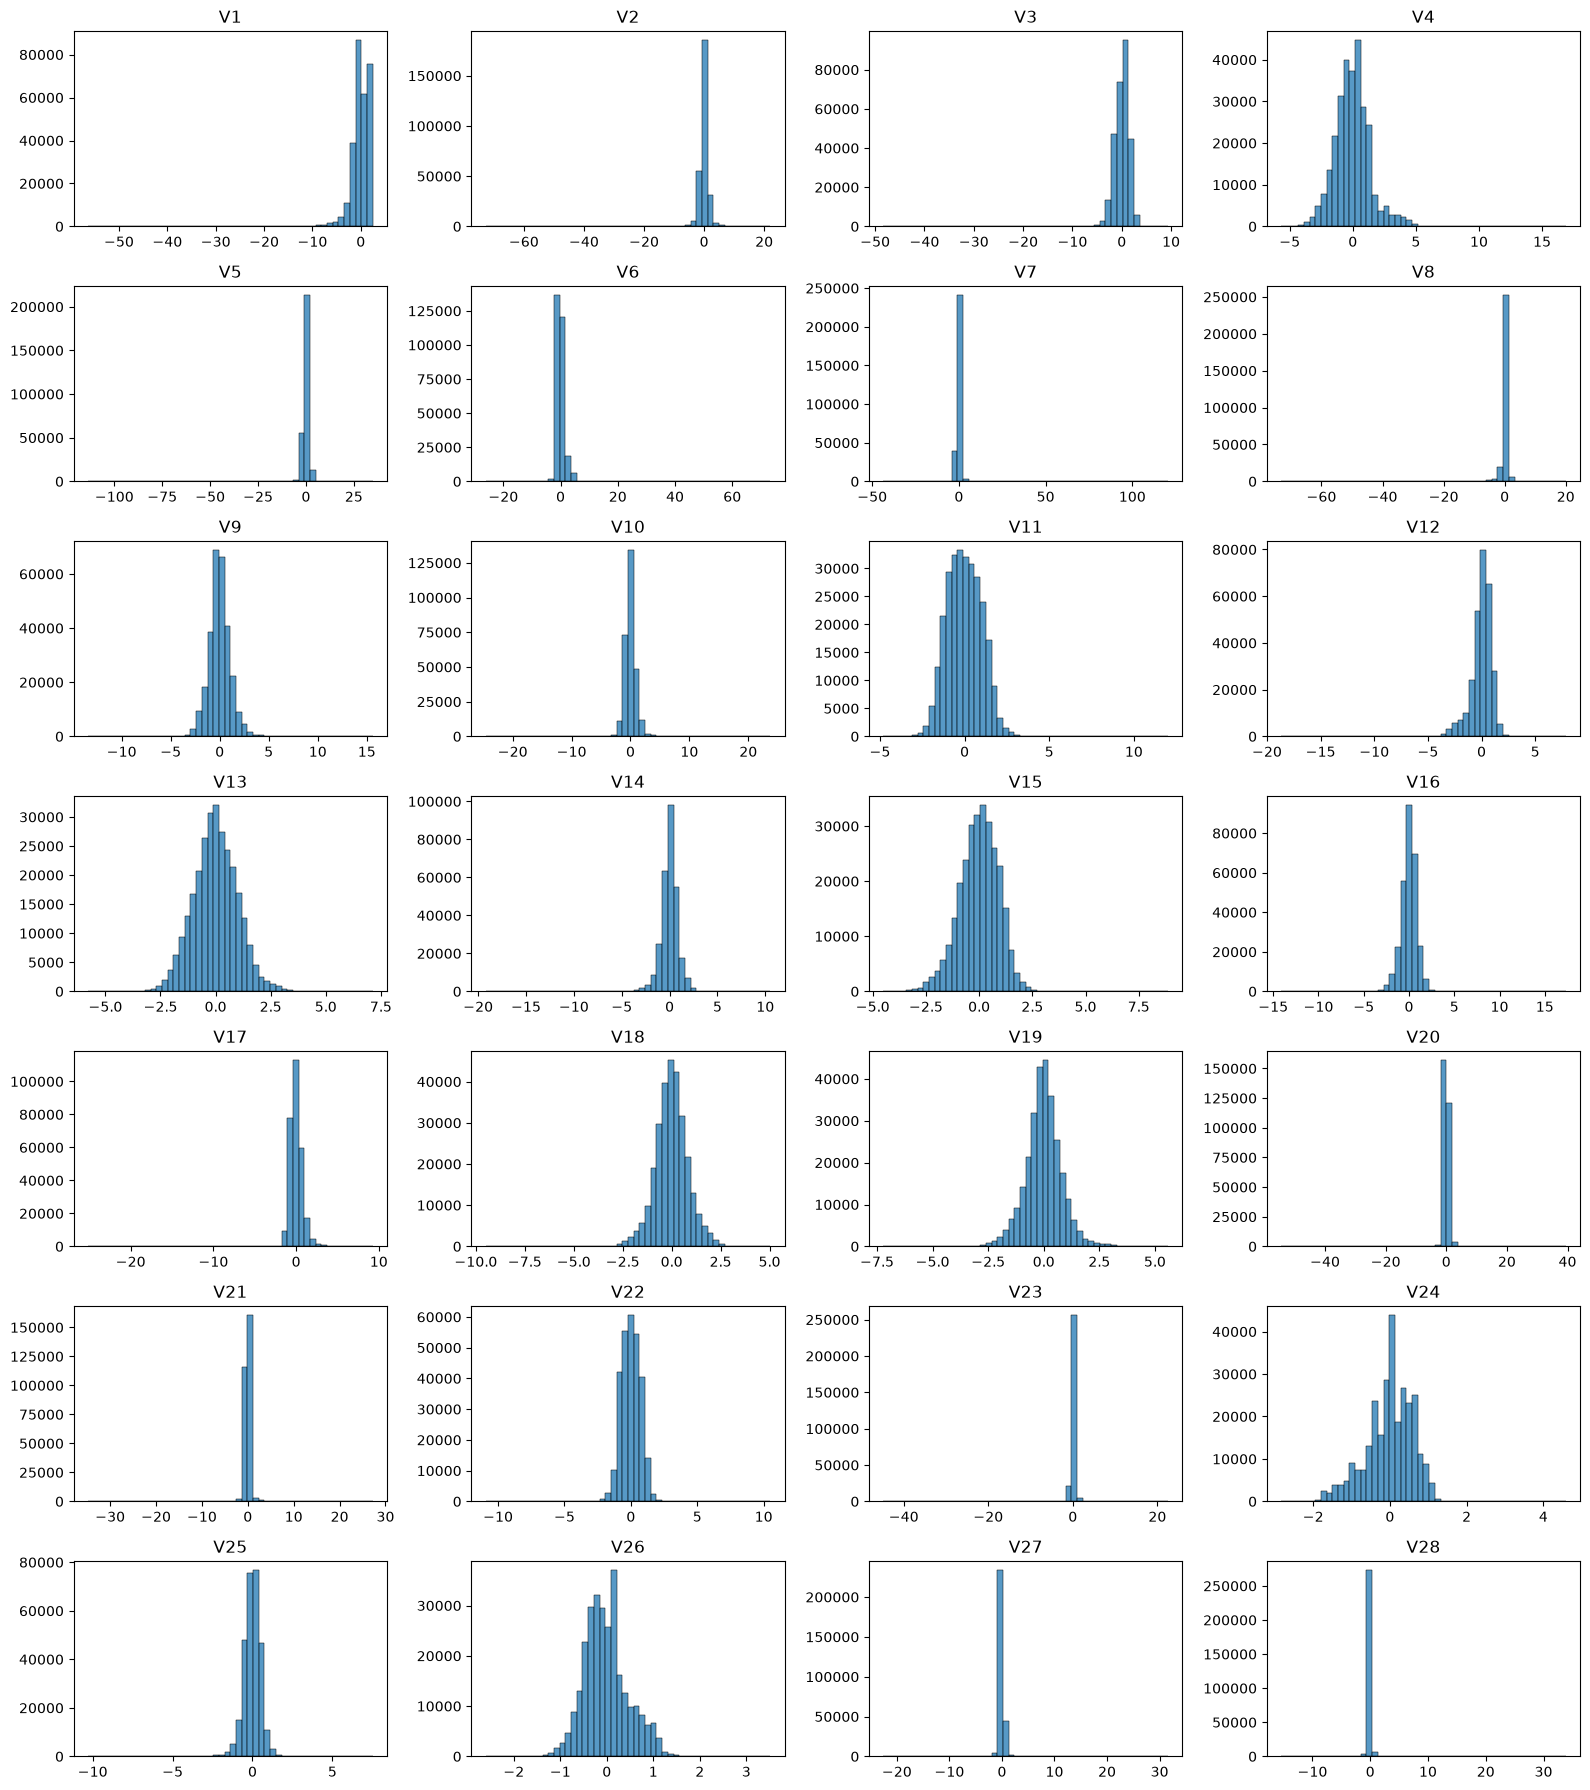

In [47]:
fig, axes = plt.subplots(7, 4, figsize=(16, 18))
for ax, col in zip(axes.ravel(), v_cols):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 6.2 Corrélation linéaire avec `Class`

Nous cherchons les variables ayant la plus forte association **linéaire** avec la cible.

In [48]:
corr_class = (
    df[v_cols + ["Class"]].corr()["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)
corr_class.head(10).round(3)

V17   -0.326
V14   -0.303
V12   -0.261
V10   -0.217
V16   -0.197
V3    -0.193
V7    -0.187
V11    0.155
V4     0.133
V18   -0.111
Name: Class, dtype: float64

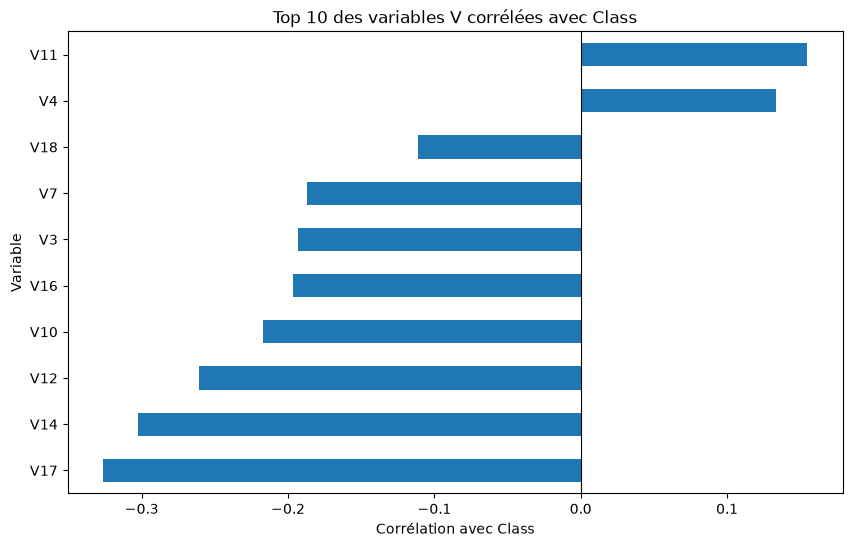

In [49]:
plt.figure(figsize=(10, 6))
corr_class.head(10).sort_values().plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 10 des variables V corrélées avec Class")
plt.xlabel("Corrélation avec Class")
plt.ylabel("Variable")
plt.show()

In [46]:
# Pour mémoire : corrélation des variables non issues de l'ACP
df[["Time", "Amount", "Amount_log", "Class"]].corr()["Class"].drop("Class").round(4)

Time         -0.0123
Amount        0.0056
Amount_log   -0.0083
Name: Class, dtype: float64

**Conclusion.** Les plus fortes corrélations linéaires en valeur absolue avec `Class` sont `V17` (-0,326), `V14` (-0,303), `V12` (-0,261), `V10` (-0,217), `V16` (-0,197), `V3` (-0,193) et `V7` (-0,187) ; `V11` et `V4` présentent des corrélations positives plus faibles.

Une corrélation élevée ne signifie pas qu'une variable sera le meilleur prédicteur dans un modèle, et une corrélation proche de zéro ne signifie pas qu'elle est inutile : une relation non linéaire ou une interaction peut être importante. Avec une cible binaire très déséquilibrée, la corrélation de Pearson est de plus sensible aux valeurs extrêmes.

### 6.3 Comparaison des distributions selon la classe

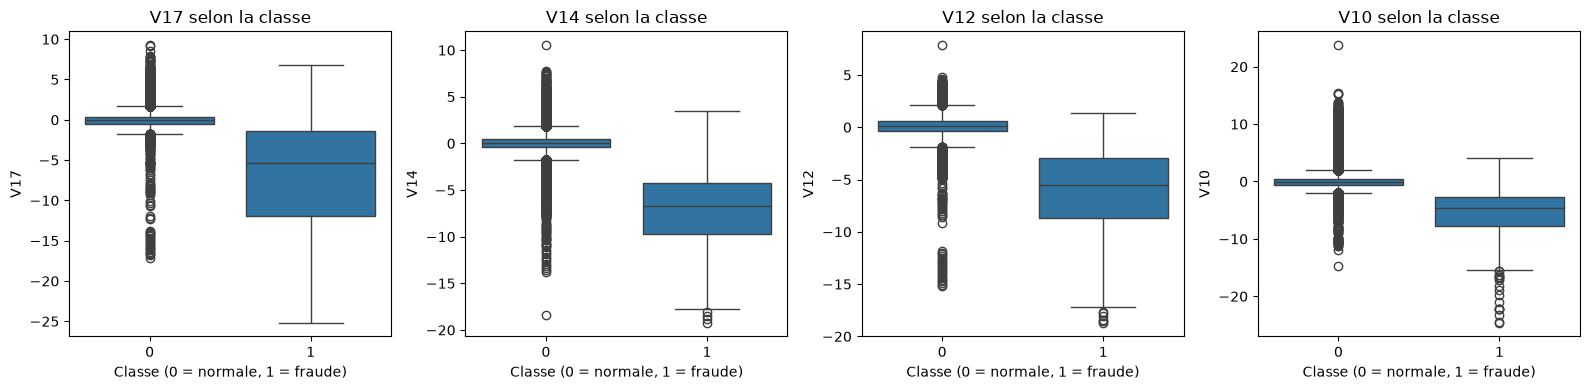

In [51]:
variables = ["V17", "V14", "V12", "V10"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, variables):
    sns.boxplot(data=df, x="Class", y=col, ax=ax)
    ax.set_title(f"{col} selon la classe")
    ax.set_xlabel("Classe (0 = normale, 1 = fraude)")
plt.tight_layout()
plt.show()

Pour `V17`, `V14`, `V12` et `V10`, les fraudes ont des valeurs **généralement plus négatives** que les transactions normales, ce qui est cohérent avec leurs corrélations négatives. On observe aussi de nombreuses valeurs extrêmes, qui ne seront pas considérées comme des erreurs.

### 6.4 Classement par AUC univariée

**Principe.** Pour une variable donnée, on prend une fraude et une transaction normale au hasard et on regarde laquelle a la **valeur numérique la plus grande**. L'AUC est la proportion de paires pour lesquelles la fraude a la valeur la plus grande :

- **AUC ≈ 0,5** : la variable ne sépare pas les classes (comme un tirage à pile ou face) ;
- **AUC proche de 1** : les fraudes ont presque toujours des valeurs plus élevées ;
- **AUC proche de 0** : les fraudes ont presque toujours des valeurs plus basses (séparation aussi forte, mais en sens inverse).

On représente `AUC - 0,5` : 0 signifie « aucune séparation » ; le signe donne le sens de l'écart.

**Intérêt par rapport à la corrélation.** L'AUC ne dépend que de l'ordre des valeurs : elle est donc insensible aux valeurs extrêmes et au déséquilibre des classes. Elle donne un classement lisible de toutes les variables, sur la même échelle.

**Limites.** Elle examine une variable à la fois (sans leurs combinaisons) et ne détecte que les relations globalement monotones. Calculée ici sur tout le jeu de données, elle sert à **explorer**, pas à **sélectionner** des variables : celles-ci sont toutes conservées.

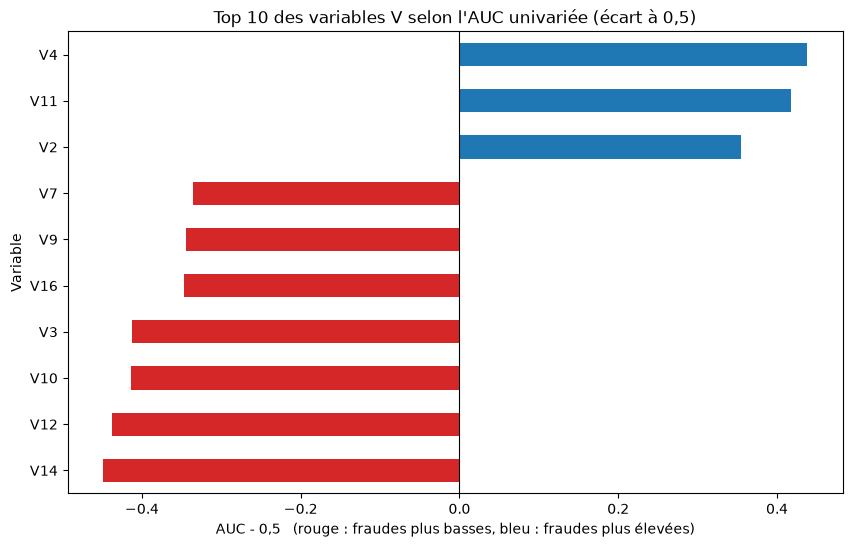

V14   -0.449
V4     0.438
V12   -0.437
V11    0.418
V10   -0.414
V3    -0.412
V2     0.355
V16   -0.347
V9    -0.344
V7    -0.336
dtype: float64

In [52]:
# AUC univariée : chaque variable est utilisée seule comme "score" de fraude
auc = pd.Series({c: roc_auc_score(df["Class"], df[c]) for c in v_cols})

# Écart signé à 0,5 : > 0 -> fraudes plutôt plus élevées, < 0 -> fraudes plutôt plus basses
auc_gap = (auc - 0.5).sort_values(key=abs, ascending=False)

top = auc_gap.head(10).sort_values()
colors = ["tab:red" if v < 0 else "tab:blue" for v in top]

plt.figure(figsize=(10, 6))
top.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 10 des variables V selon l'AUC univariée (écart à 0,5)")
plt.xlabel("AUC - 0,5   (rouge : fraudes plus basses, bleu : fraudes plus élevées)")
plt.ylabel("Variable")
plt.show()

auc_gap.head(10).round(3)

In [53]:
# Comparaison des deux classements (corrélation de Pearson vs AUC univariée)
comparaison = pd.DataFrame({
    "corr_Class": corr_class,
    "ecart_AUC": auc_gap,
})
comparaison["rang_corr"] = comparaison["corr_Class"].abs().rank(ascending=False).astype(int)
comparaison["rang_AUC"] = comparaison["ecart_AUC"].abs().rank(ascending=False).astype(int)

a_afficher = comparaison[(comparaison["rang_corr"] <= 10) | (comparaison["rang_AUC"] <= 10)]
a_afficher.sort_values("rang_AUC").round(3)

,corr_Class,ecart_AUC,rang_corr,rang_AUC
V14,-0.303,-0.449,2,1
V4,0.133,0.438,9,2
V12,-0.261,-0.437,3,3
V11,0.155,0.418,8,4
V10,-0.217,-0.414,4,5
V3,-0.193,-0.412,6,6
V2,0.091,0.355,14,7
V16,-0.197,-0.347,5,8
V9,-0.098,-0.344,12,9
V7,-0.187,-0.336,7,10


**Conclusion.** Le classement par AUC univariée met en avant `V14`, `V12`, `V10` et `V3` (écart d'environ -0,41 à -0,45, fraudes plus basses) ainsi que `V4` et `V11` (environ +0,42 à +0,44, fraudes plus élevées) ; `V16`, `V9`, `V7` (fraudes plus basses) et `V2` (fraudes plus élevées) viennent ensuite. La séparation est forte : une seule variable suffit déjà à classer correctement une grande majorité des paires fraude / transaction normale.

Les deux classements ne coïncident pas : `V17`, la plus corrélée linéairement avec `Class`, ne figure pas dans le top 10 par AUC (voir son rang dans le tableau ci-dessus), ce qui suggère que sa corrélation est en partie portée par des valeurs extrêmes. À l'inverse, `V4`, `V11`, `V2` et `V9` apparaissent bien classées par AUC alors que leur corrélation est plus faible : une corrélation faible n'implique pas une variable inutile.

Ce classement est **indicatif** : toutes les variables `V` sont conservées pour la modélisation.

## 7. Synthèse, limites et suite du projet

### 7.1 Principaux constats

| Thème | Constat |
|---|---|
| Qualité des données | aucune valeur manquante ; 1 081 doublons exacts, dont 19 fraudes (3,86 % des fraudes) |
| Cible | très déséquilibrée : 492 fraudes sur 284 807 transactions (0,17 %) |
| `Amount` | très asymétrique ; les fraudes sont plus souvent de très faible montant (médiane ≈ 9,3 contre ≈ 22) et plus dispersées ; insuffisante seule |
| `Time` / heure | taux de fraude nettement plus élevé aux heures 2 à 4 du cycle (jusqu'à environ 10 fois le taux global) et à l'heure 11 ; origine de `Time` supposée |
| `V1` à `V28` | composantes d'ACP anonymisées et décorrélées ; plusieurs séparent déjà fortement les classes (`V14`, `V12`, `V10`, `V3`, `V4`, `V11`) |

### 7.2 Choix pour la modélisation

- **Doublons** : conservés, avec une analyse de sensibilité (modèle A avec doublons, modèle B sans doublons) et une vérification de l'absence de fuite entre jeux d'entraînement et de test.
- **Métriques** : PR-AUC en priorité, avec rappel et précision à un seuil choisi ; l'accuracy n'est pas utilisée.
- **Découpage** : stratifié sur `Class`, avec un jeu de validation pour choisir le seuil, et un jeu de test utilisé une seule fois.
- **Variables** : toutes les `V` conservées ; `Amount_log` pour la régression logistique ; `Hour` encodée de façon cyclique (ou indicateur « nuit ») pour la régression logistique, brute pour les arbres.
- **Déséquilibre** : pondération des classes (`class_weight`, `scale_pos_weight`) ; tout rééchantillonnage éventuel uniquement sur le jeu d'entraînement.

### 7.3 Limites

- L'origine de `Time` n'est pas documentée : l'« heure du cycle » repose sur l'hypothèse `Time = 0` ≈ minuit.
- Les variables `V` sont anonymisées : leur contribution peut être mesurée mais pas expliquée en termes métier. L'ACP a été calculée par le fournisseur sur l'ensemble des transactions, y compris celles qui serviront de test.
- Les données ne couvrent que **deux jours** et **492 fraudes** : les estimations par heure sont bruitées et rien ne garantit une généralisation à d'autres périodes.
- Les analyses exploratoires (AUC, taux par heure) sont calculées sur tout le jeu de données : elles servent à comprendre, pas à sélectionner des variables.
- Un découpage chronologique (entraînement sur le début, test sur la fin) serait plus réaliste qu'un découpage aléatoire ; il n'est pas retenu ici faute de recul temporel suffisant.

## 8. Sauvegarde de la base enrichie

Aucune ligne n'est supprimée : la base sauvegardée est la base d'origine **enrichie** de variables dérivées (`Amount_category`, `Amount_log`, `Time_bin`, `Time_hours`, `Hour_cycle`, `Hour`, `Day`).

In [54]:
OUT_PATH = "../data/processed/df_enrichi.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

df.to_csv(OUT_PATH, index=False)

print("Base enrichie sauvegardée avec succès :", OUT_PATH)
print("Dimensions :", df.shape)

Base enrichie sauvegardée avec succès : ../data/processed/df_enrichi.csv
Dimensions : (284807, 38)
